# 02 · Crop suitability model

Which classifier should turn N, P, K, pH, temperature, humidity and rainfall into crop suitability?

- **Models:** Logistic Regression, Random Forest, XGBoost, LightGBM.
- **Evaluation:** stratified 5-fold CV, seed 42. Accuracy, macro F1, and top-3 accuracy (the app shows 3 crops).
- **Humidity test:** every model is trained with and without humidity. Kaggle humidity doesn't match NASA POWER
  (errors of 20–38 points in `2026-10-29_weather_vs_kaggle.csv`), so the app may have to do without it.

Outputs: `research/results/2026-11-03_crop_model_cv.csv`, figures in `research/figures/`.
The app model is trained and saved in notebook 05, section 5 (Nov 3 update).

In [1]:
import sys
sys.path.insert(0, '../project')
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, make_scorer, top_k_accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from xgboost import XGBClassifier

import data

SEED = 42
RESULTS, FIGS = Path('../research/results'), Path('../research/figures')
FIGS.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 200)

## 1. Data

In [2]:
crops = data.kaggle_crops()
ALL = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
NO_HUM = [f for f in ALL if f != 'humidity']
enc = LabelEncoder()
y = enc.fit_transform(crops.label)
print(crops.shape, len(enc.classes_), 'crops,', np.bincount(y).min(), 'rows each')
print('duplicate rows:', crops.duplicated().sum(), '| missing values:', crops.isna().sum().sum())

(2200, 8) 22 crops, 100 rows each
duplicate rows: 0 | missing values: 0


How separable are the crops? Each cell is a crop's mean feature value, scaled 0–1 across crops.
Crops with a distinctive row (e.g. high K for apple and grapes, high rainfall for rice) should be easy to classify.

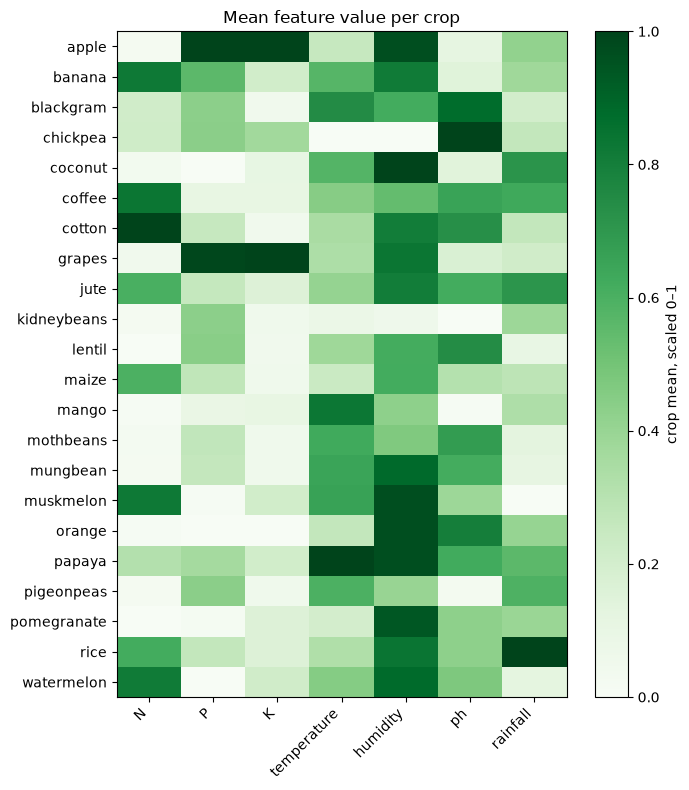

In [3]:
means = crops.groupby('label')[ALL].mean()
scaled = (means - means.min()) / (means.max() - means.min())
fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(scaled, cmap='Greens', aspect='auto')
ax.set_xticks(range(len(ALL)), ALL, rotation=45, ha='right')
ax.set_yticks(range(len(scaled)), scaled.index)
fig.colorbar(im, ax=ax, label='crop mean, scaled 0–1')
ax.set_title('Mean feature value per crop')
fig.tight_layout()
fig.savefig(FIGS / 'crop_feature_means.png', dpi=150)

## 2. Cross-validated comparison

In [4]:
models = {
    'LogReg': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'RandomForest': RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.1, random_state=SEED, n_jobs=-1),
    'LightGBM': LGBMClassifier(n_estimators=300, random_state=SEED, n_jobs=-1, verbose=-1),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    'accuracy': 'accuracy',
    'f1_macro': 'f1_macro',
    'top3': make_scorer(top_k_accuracy_score, k=3, labels=np.arange(len(enc.classes_)), response_method='predict_proba'),
}

rows = []
for feats_name, feats in [('with humidity', ALL), ('without humidity', NO_HUM)]:
    for name, model in models.items():
        s = cross_validate(model, crops[feats], y, cv=cv, scoring=scoring)
        rows.append({'model': name, 'features': feats_name, 'n_features': len(feats),
                     **{f'{m}_mean': s[f'test_{m}'].mean() for m in scoring},
                     **{f'{m}_std': s[f'test_{m}'].std() for m in scoring},
                     'fit_seconds': s['fit_time'].mean()})
res = pd.DataFrame(rows).round(4)
res.to_csv(RESULTS / '2026-11-03_crop_model_cv.csv', index=False)
res

,model,features,n_features,accuracy_mean,f1_macro_mean,top3_mean,accuracy_std,f1_macro_std,top3_std,fit_seconds
0,LogReg,with humidity,7,0.9709,0.9707,0.9991,0.0022,0.0023,0.0018,0.0506
1,RandomForest,with humidity,7,0.9950,0.9950,1.0000,0.0027,0.0027,0.0000,0.3771
2,XGBoost,with humidity,7,0.9932,0.9932,0.9991,0.0029,0.0029,0.0011,1.0453
3,LightGBM,with humidity,7,0.9927,0.9927,1.0000,0.0030,0.0031,0.0000,2.1050
4,LogReg,without humidity,6,0.9009,0.8971,0.9918,0.0059,0.0067,0.0060,0.0418
5,RandomForest,without humidity,6,0.9836,0.9837,1.0000,0.0053,0.0052,0.0000,0.3857
6,XGBoost,without humidity,6,0.9791,0.9790,0.9986,0.0086,0.0086,0.0011,1.3127
7,LightGBM,without humidity,6,0.9814,0.9814,0.9982,0.0039,0.0039,0.0017,2.5855


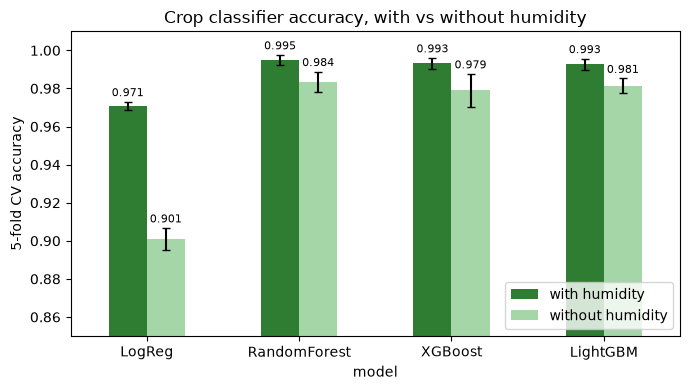

In [5]:
pivot = res.pivot(index='model', columns='features', values='accuracy_mean').loc[list(models)]
err = res.pivot(index='model', columns='features', values='accuracy_std').loc[list(models)]
ax = pivot.plot.bar(yerr=err, figsize=(7, 4), rot=0, capsize=3, color=['#2e7d32', '#a5d6a7'])
ax.set_ylim(0.85, 1.01)
ax.set_ylabel('5-fold CV accuracy')
ax.set_title('Crop classifier accuracy, with vs without humidity')
for c in [c for c in ax.containers if hasattr(c, 'patches')]:
    ax.bar_label(c, fmt='%.3f', fontsize=8, padding=2)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(FIGS / 'crop_model_accuracy.png', dpi=150)

## 3. Pick the app model

The app gets humidity from NASA POWER, and that humidity doesn't match Kaggle's. A model that leans on humidity
will be fed values it never saw in training. So the app model is the best model **without humidity**,
unless dropping it costs a lot of accuracy.

In [6]:
no_hum = res[res.features == 'without humidity'].sort_values('accuracy_mean', ascending=False)
best = no_hum.iloc[0]
with_hum = res[(res.model == best.model) & (res.features == 'with humidity')].iloc[0]
print(f"Best without humidity: {best.model}  acc {best.accuracy_mean:.4f} ± {best.accuracy_std:.4f}, top-3 {best.top3_mean:.4f}")
print(f"Same model with humidity: acc {with_hum.accuracy_mean:.4f}  (cost of dropping humidity: {with_hum.accuracy_mean - best.accuracy_mean:+.4f})")

Best without humidity: RandomForest  acc 0.9836 ± 0.0053, top-3 1.0000
Same model with humidity: acc 0.9950  (cost of dropping humidity: +0.0114)


Which crops get confused without humidity? Out-of-fold predictions, so every row is predicted by a model that didn't train on it.

Most confused pairs (true → predicted):
row_0       col_0      
rice        jute           8
pigeonpeas  kidneybeans    5
mothbeans   mungbean       4
lentil      mungbean       4
blackgram   mothbeans      2
jute        rice           2
mungbean    lentil         2
mothbeans   blackgram      2


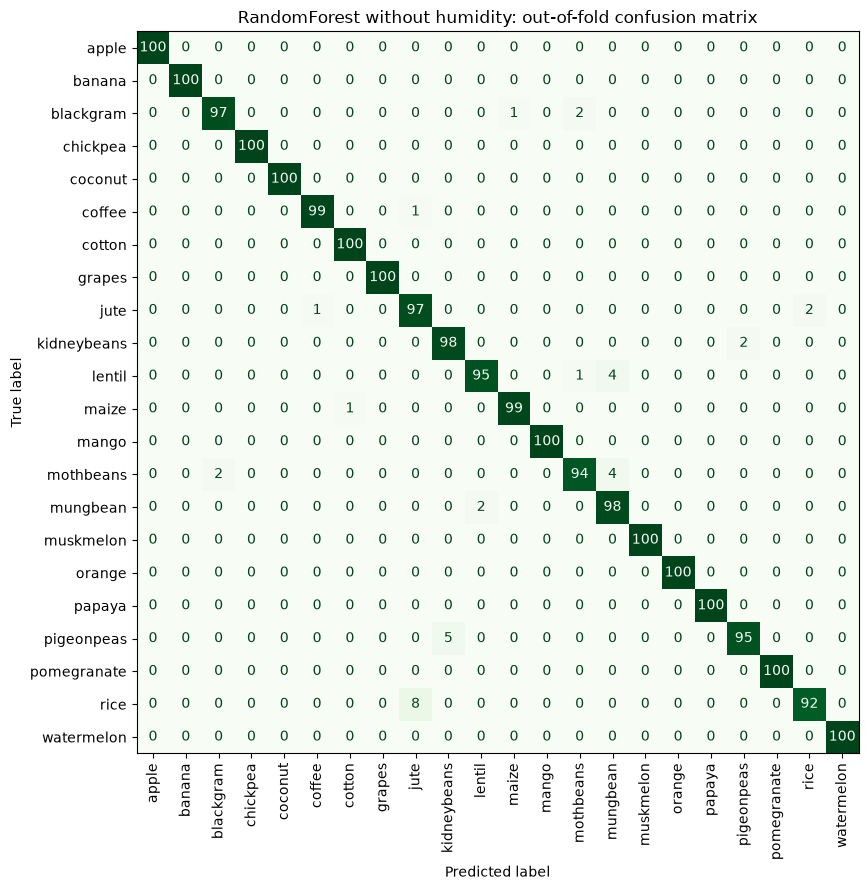

In [7]:
best_model = models[best.model]
oof = cross_val_predict(best_model, crops[NO_HUM], y, cv=cv)
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay.from_predictions(enc.inverse_transform(y), enc.inverse_transform(oof), ax=ax,
                                        xticks_rotation=90, colorbar=False, cmap='Greens')
ax.set_title(f'{best.model} without humidity: out-of-fold confusion matrix')
fig.tight_layout()
fig.savefig(FIGS / 'crop_model_confusion.png', dpi=150)

pairs = pd.crosstab(enc.inverse_transform(y), enc.inverse_transform(oof)).stack()
pairs = pairs[[t != p for t, p in pairs.index]]
print('Most confused pairs (true → predicted):')
print(pairs.sort_values(ascending=False).head(8).to_string())

In [8]:
per_crop = pd.Series(oof == y, index=enc.inverse_transform(y)).groupby(level=0).mean().sort_values()
print('Per-crop recall, worst first:')
print(per_crop.head(8).round(3).to_string())

Per-crop recall, worst first:
rice           0.92
mothbeans      0.94
pigeonpeas     0.95
lentil         0.95
blackgram      0.97
jute           0.97
kidneybeans    0.98
mungbean       0.98


## 4. Train on all data: feature importance

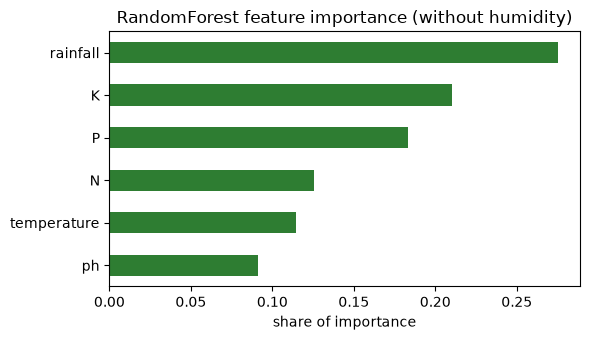

In [9]:
best_model.fit(crops[NO_HUM], y)
imp = getattr(best_model, 'feature_importances_', None)
if imp is not None:
    s = pd.Series(imp, index=NO_HUM).sort_values()
    ax = (s / s.sum()).plot.barh(figsize=(6, 3.5), color='#2e7d32')
    ax.set_xlabel('share of importance')
    ax.set_title(f'{best.model} feature importance (without humidity)')
    plt.tight_layout()
    plt.savefig(FIGS / 'crop_model_importance.png', dpi=150)

## Findings (Nov 3)

- Tree models all score **~99%** with humidity and **~98%** without; differences between RF, XGBoost and LightGBM are within one std.
  Logistic Regression is clearly worse (97% → 90%), so the crops aren't linearly separable without humidity.
- Dropping humidity costs Random Forest **1.1 points** of accuracy and **nothing** in top-3 accuracy (100% either way).
  Since the app shows 3 crops, this is a cheap price for not feeding the model mismatched NASA humidity.
- Errors without humidity are between crops that look alike in soil and rain: rice ↔ jute, pigeonpeas → kidneybeans,
  and the pulses (mothbeans, mungbean, lentil, blackgram).
- **Choice: Random Forest without humidity.** Notebook 05 then added weather-noise augmentation and isotonic
  calibration; that version is the app model (`models/crop_model.joblib`, saved by notebook 05).
- Caveat for the paper: near-perfect scores mostly say the Kaggle data is clean and well separated (likely synthetic),
  not that the model will work on real farms. The real-world check (Nov 5–6) tests that.